<a href="https://colab.research.google.com/github/Mutisojr34/SemProject_MLEngine/blob/main/KMeans_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ICS 3202 – Project Deliverable 2: ML Engine (K-Means Base Model)

**Project:** UniPool – AI-assisted shared mobility app for Strathmore University student commuters.

**Goal of the ML engine:** group trips with **similar routes** (similar start and end points) so the app can match students who can share a ride and split the fare.

**Why this dataset:** we do not yet have real student trip data, so Porto taxi trips (start point, end point, time) are used as a stand-in with the same structure.

**ML approach:** unsupervised learning → **K-Means clustering** on the route of each trip (pick-up and drop-off latitude/longitude).

**Other models used for validation (Q4):** MiniBatch K-Means and Gaussian Mixture.

**Contents**
1. Load the data
2. Data cleaning
3. Exploratory Data Analysis (EDA) and observations
4. Modelling with K-Means (elbow method, silhouette, train/test check, matching demo)
5. Validation with other models

## 1. Load the data
In this section we import the libraries we need, read the CSV file and take a first look at it.
We want to know how big the data is, what each column contains, and whether anything is missing.

In [2]:
# Libraries for data handling and graphs
# tables (DataFrames)
import pandas as pd



In [3]:
 # maths on arrays
 import numpy as np

In [4]:
 # graphs
 import matplotlib.pyplot as plt


In [5]:
# Machine learning tools from scikit-learn
# clustering models
from sklearn.cluster import KMeans, MiniBatchKMeans
# another clustering model
from sklearn.mixture import GaussianMixture
# cluster quality scores
from sklearn.metrics import silhouette_score, davies_bouldin_score
# split data into train/test
from sklearn.model_selection import train_test_split
# default graph size
plt.rcParams['figure.figsize'] = (8, 4)





In [6]:
# Read the raw file into a table
df = pd.read_csv('porto_trajectories_all.csv')

1.1 Getting to know how big the data is, what each column contains, and whether anything is missing.

In [7]:
# Show number of rows and columns, then the first 5 rows
print('Rows, columns:', df.shape)
df.head()

Rows, columns: (1674160, 5)


,taxi_id,trajectory_id,timestamp,source_point,target_point
0,20000589,1372636858620000589,2013-07-01 00:00:58,POINT(-8.618643 41.141412),POINT(-8.630838 41.154489)
1,20000596,1372637303620000596,2013-07-01 00:08:23,POINT(-8.639847 41.159826),POINT(-8.66574 41.170671)
2,20000320,1372636951620000320,2013-07-01 00:02:31,POINT(-8.612964 41.140359),POINT(-8.61597 41.14053)
3,20000520,1372636854620000520,2013-07-01 00:00:54,POINT(-8.574678 41.151951),POINT(-8.607996 41.142915)
4,20000337,1372637091620000337,2013-07-01 00:04:51,POINT(-8.645994 41.18049),POINT(-8.687268 41.178087)


In [8]:
# Column names, data types and non-null counts
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1674160 entries, 0 to 1674159
Data columns (total 5 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   taxi_id        1674160 non-null  int64 
 1   trajectory_id  1674160 non-null  int64 
 2   timestamp      1674160 non-null  object
 3   source_point   1674160 non-null  object
 4   target_point   1674160 non-null  object
dtypes: int64(2), object(3)
memory usage: 63.9+ MB


In [9]:
# Count missing values in each column
print('\nMissing values per column:')
print(df.isnull().sum())


Missing values per column:
taxi_id          0
trajectory_id    0
timestamp        0
source_point     0
target_point     0
dtype: int64


Observations -

**What we found:** the data has one row per taxi trip. The locations (`source_point`, `target_point`) are stored as text like `POINT(lon lat)`, and `timestamp` is also text, so they must be converted before modelling.
There are no missing values, but we still need to check for duplicates and wrong GPS points.

## 2. Data cleaning
Models learn from the data they are given, so wrong or repeated rows would give wrong clusters.
We clean the data in five steps and count how many rows each step removes.

### Step 1: Remove duplicates
Each trip should appear only once. `trajectory_id` is a unique trip number, so a repeated ID means a repeated trip.

In [10]:
# rows before cleaning
n_start = len(df)
print('Fully duplicated rows:', df.duplicated().sum())
print('Repeated trajectory_id:', df['trajectory_id'].duplicated().sum())

# Keep only the first row of each trajectory_id
df = df.drop_duplicates(subset='trajectory_id')
 # rows removed in this step
n_dups = n_start - len(df)
print('Rows removed:', n_dups)

Fully duplicated rows: 2
Repeated trajectory_id: 11
Rows removed: 11


### Step 2: Split the POINT text into numbers
A model needs numbers, not text. We pull the longitude and latitude out of each `POINT(lon lat)` text and save them in four new columns.

In [11]:
# Pull the two numbers out of the text 'POINT(lon lat)'
src = df['source_point'].str.extract(r'POINT\((-?[\d.]+) (-?[\d.]+)\)').astype(float)
tgt = df['target_point'].str.extract(r'POINT\((-?[\d.]+) (-?[\d.]+)\)').astype(float)

# s = start (pick-up)
df['slon'], df['slat'] = src[0], src[1]

# t = target (drop-off)
df['tlon'], df['tlat'] = tgt[0], tgt[1]

# The old text columns are no longer needed
df = df.drop(columns=['source_point', 'target_point'])

# Check the range of the new columns
df[['slon', 'slat', 'tlon', 'tlat']].describe()





,slon,slat,tlon,tlat
count,1.674149e+06,1.674149e+06,1.674149e+06,1.674149e+06
mean,-8.617299e+00,4.115702e+01,-8.620153e+00,4.116235e+01
std,2.783450e-02,2.085306e-02,3.787034e-02,3.613033e-02
min,-1.215453e+01,3.718483e+01,-1.347646e+01,3.731378e+01
25%,-8.628822e+00,4.114785e+01,-8.640756e+00,4.114869e+01
50%,-8.612739e+00,4.115434e+01,-8.615223e+00,4.115782e+01
75%,-8.603748e+00,4.116317e+01,-8.602776e+00,4.117081e+01
max,-4.816116e+00,5.103712e+01,-5.793111e+00,4.435162e+01


**What we found:** the minimum and maximum values show bad GPS points. Some latitudes are around 51 and some longitudes around -4.8, which are **not in Porto** (Porto is near latitude 41.15 and longitude -8.61). We remove these in Step 4.

### Step 3: Convert the timestamp and create time features
The timestamp is text. We convert it to a real date/time so we can get the hour, weekday and month. These help us understand demand patterns and, later, match riders who travel at the same time.


In [12]:
# Text -> date and time
df['timestamp'] = pd.to_datetime(df['timestamp'])

# New columns taken from the timestamp
 # 0 to 23
df['hour'] = df['timestamp'].dt.hour

 # Monday, Tuesday, ...
df['weekday'] = df['timestamp'].dt.day_name()

# 1 to 12
df['month'] = df['timestamp'].dt.month

# Group the hours into parts of the day
def part_of_day(h):
    if 5 <= h < 12:  return 'Morning'
    if 12 <= h < 17: return 'Afternoon'
    if 17 <= h < 22: return 'Evening'
    return 'Night'
df['part_of_day'] = df['hour'].apply(part_of_day)

print('Date range:', df['timestamp'].min(), 'to', df['timestamp'].max())

Date range: 2013-07-01 00:00:53 to 2014-06-30 23:59:14


### Step 4: Remove points outside Porto
Our app works in one city, so trips with GPS points far away are errors. We draw a box around Porto (wide enough to include the airport) and keep only trips that start and end inside it.

In [13]:
# True if the point is inside the box around Porto
def inside_porto(lon, lat):
    return lon.between(-8.75, -8.50) & lat.between(41.10, 41.30)

n_before = len(df)
# Keep a trip only if BOTH its start and end are inside Porto
df = df[inside_porto(df['slon'], df['slat']) & inside_porto(df['tlon'], df['tlat'])]
n_outside = n_before - len(df)
print('Rows removed (outside Porto):', n_outside)

Rows removed (outside Porto): 19997


### Step 5: Remove trips with (almost) no distance
Some trips start and end at nearly the same place. These are probably cancelled trips or GPS errors, and they are not useful for matching riders on a route. We calculate each trip's distance and remove trips shorter than 100 m.

In [14]:
# Straight-line distance between two GPS points in km (haversine formula)
def haversine(lon1, lat1, lon2, lat2):

    # degrees -> radians
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
     # 6371 = Earth radius in km
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df['km'] = haversine(df['slon'], df['slat'], df['tlon'], df['tlat'])

n_before = len(df)

 # keep trips of at least 0.1 km
df = df[df['km'] >= 0.1]
n_short = n_before - len(df)
print('Rows removed (shorter than 0.1 km):', n_short)

Rows removed (shorter than 0.1 km): 32606


### Cleaning summary
The graphs below show how much data we kept and why rows were removed.

Original rows : 1674160
Final rows    : 1621546 (96.9% kept)


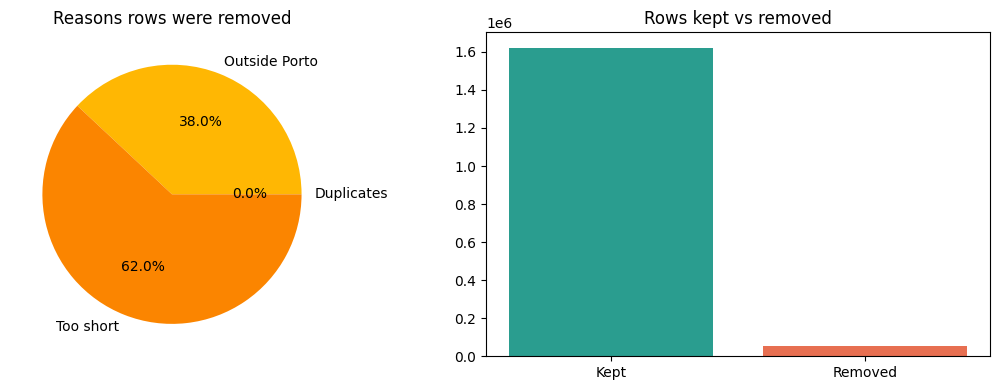

In [15]:
n_final = len(df)
print('Original rows :', n_start)
print('Final rows    :', n_final, f'({n_final/n_start:.1%} kept)')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Pie chart: reasons rows were removed
ax[0].pie([n_dups, n_outside, n_short],
          labels=['Duplicates', 'Outside Porto', 'Too short'],
          autopct='%1.1f%%', colors=['#8ecae6', '#ffb703', '#fb8500'])
ax[0].set_title('Reasons rows were removed')

# Bar chart: rows kept vs removed
ax[1].bar(['Kept', 'Removed'], [n_final, n_start - n_final], color=['#2a9d8f', '#e76f51'])
ax[1].set_title('Rows kept vs removed')
plt.tight_layout(); plt.show()

In [16]:
# This is the final clean dataset we use for modelling
df = df.reset_index(drop=True)
df.head()

,taxi_id,trajectory_id,timestamp,slon,slat,tlon,tlat,hour,weekday,month,part_of_day,km
0,20000589,1372636858620000589,2013-07-01 00:00:58,-8.618643,41.141412,-8.630838,41.154489,0,Monday,7,Night,1.776808
1,20000596,1372637303620000596,2013-07-01 00:08:23,-8.639847,41.159826,-8.665740,41.170671,0,Monday,7,Night,2.480360
2,20000320,1372636951620000320,2013-07-01 00:02:31,-8.612964,41.140359,-8.615970,41.140530,0,Monday,7,Night,0.252442
3,20000520,1372636854620000520,2013-07-01 00:00:54,-8.574678,41.151951,-8.607996,41.142915,0,Monday,7,Night,2.965199
4,20000337,1372637091620000337,2013-07-01 00:04:51,-8.645994,41.180490,-8.687268,41.178087,0,Monday,7,Night,3.464589


## 3. Exploratory Data Analysis (EDA)
EDA means looking at the clean data with numbers and graphs to understand it before modelling.
We look at **when** people travel (hour, weekday, month), **how far** they travel, **where** trips start, and how active the taxis are.

In [17]:
# Summary numbers for trip distance (km)
df['km'].describe()

,km
count,1.621546e+06
mean,3.249909e+00
std,2.406751e+00
min,1.000130e-01
25%,1.583325e+00
50%,2.629276e+00
75%,4.148804e+00
max,2.059728e+01


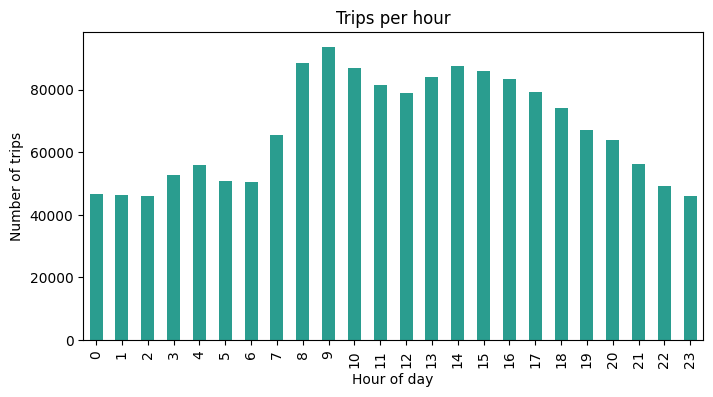

In [18]:
# Trips per hour of the day -> shows the busy and quiet times
df['hour'].value_counts().sort_index().plot(kind='bar', color='#2a9d8f')
plt.title('Trips per hour'); plt.xlabel('Hour of day'); plt.ylabel('Number of trips')
plt.show()

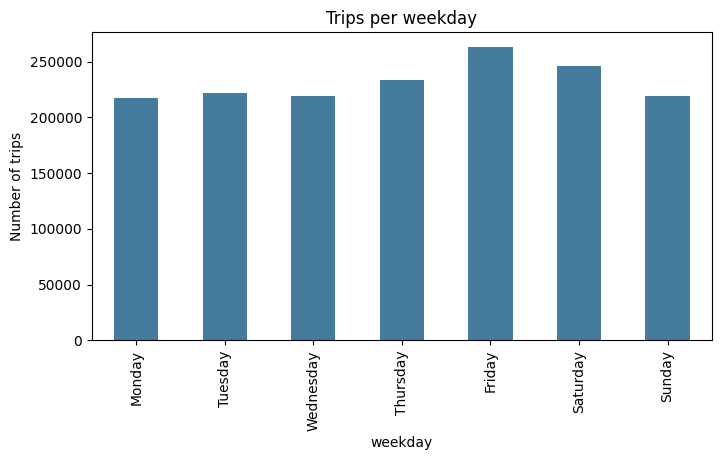

In [19]:
# Trips per weekday -> shows the busy and quiet days
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
df['weekday'].value_counts().reindex(order).plot(kind='bar', color='#457b9d')   # reindex puts days in order
plt.title('Trips per weekday'); plt.ylabel('Number of trips')
plt.show()

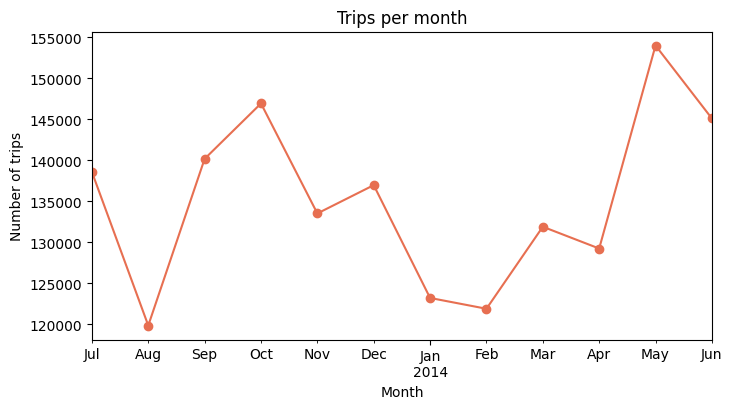

In [20]:
# Trips per month -> shows changes through the year
df.groupby(df['timestamp'].dt.to_period('M')).size().plot(marker='o', color='#e76f51')
plt.title('Trips per month'); plt.xlabel('Month'); plt.ylabel('Number of trips')
plt.show()

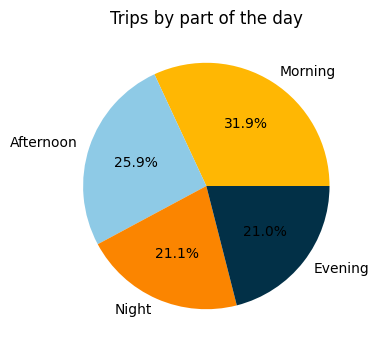

In [21]:
# Pie chart: share of trips in each part of the day
df['part_of_day'].value_counts().plot(kind='pie', autopct='%1.1f%%',
                                      colors=['#ffb703', '#8ecae6', '#fb8500', '#023047'])
plt.title('Trips by part of the day'); plt.ylabel('')
plt.show()

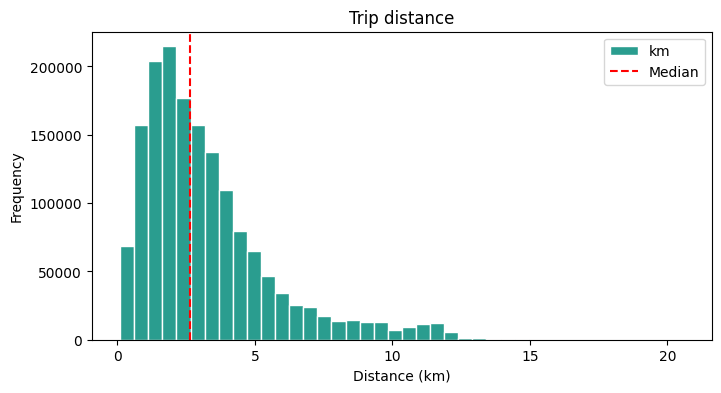

In [22]:
# Histogram: how long are the trips?
df['km'].plot(kind='hist', bins=40, color='#2a9d8f', edgecolor='white')
plt.axvline(df['km'].median(), color='red', linestyle='--', label='Median')   # red line = middle value
plt.title('Trip distance'); plt.xlabel('Distance (km)'); plt.legend()
plt.show()

Number of taxis: 439
count     439.000000
mean     3693.726651
std      1446.811452
min         7.000000
25%      2622.500000
50%      3614.000000
75%      4784.000000
max      7477.000000
Name: count, dtype: float64


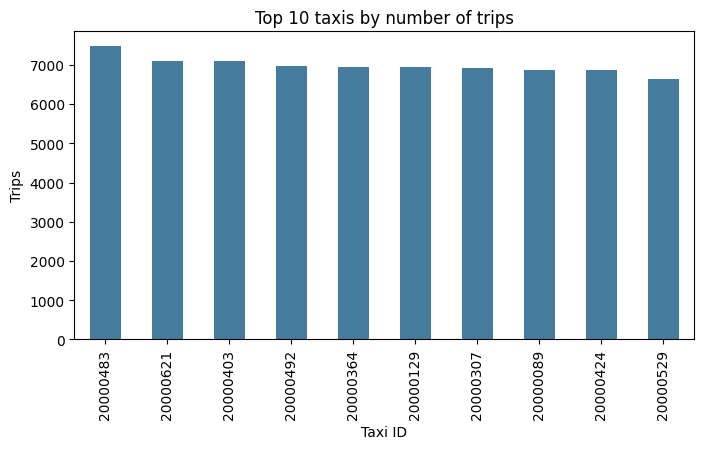

In [23]:
# How many trips does each taxi do?
trips_per_taxi = df['taxi_id'].value_counts()
print('Number of taxis:', len(trips_per_taxi))
print(trips_per_taxi.describe())

trips_per_taxi.head(10).plot(kind='bar', color='#457b9d')       # the 10 busiest taxis
plt.title('Top 10 taxis by number of trips'); plt.xlabel('Taxi ID'); plt.ylabel('Trips')
plt.show()

In [24]:
# Numbers we use in the observations below
 # hour with most trips
peak = df['hour'].value_counts().idxmax()

# hour with fewest trips
quiet = df['hour'].value_counts().idxmin()
print('Busiest hour:', peak, '| Quietest hour:', quiet)
print('Weekday counts:'); print(df['weekday'].value_counts()[order])
print('Part of day share (%):'); print((df['part_of_day'].value_counts(normalize=True)*100).round(1))
mm = df.groupby(df['timestamp'].dt.to_period('M')).size()
print('Busiest month:', mm.idxmax(), mm.max(), '| Quietest month:', mm.idxmin(), mm.min())
print('Median trip km:', round(df['km'].median(), 2), '| 90% of trips under', round(df['km'].quantile(0.9), 2), 'km')

Busiest hour: 9 | Quietest hour: 23
Weekday counts:
weekday
Monday       217274
Tuesday      222270
Wednesday    219723
Thursday     233577
Friday       263378
Saturday     245964
Sunday       219360
Name: count, dtype: int64
Part of day share (%):
part_of_day
Morning      31.9
Afternoon    25.9
Night        21.1
Evening      21.0
Name: proportion, dtype: float64
Busiest month: 2014-05 154011 | Quietest month: 2013-08 119867
Median trip km: 2.63 | 90% of trips under 6.39 km


### EDA observations
1. **Demand peaks in the morning rush.** Trips are highest around 9 AM and lowest late at night. Mornings (5 AM–12 PM) hold the biggest share of trips (about 32%), while afternoon, evening and night are each about 21–26%.
2. **Friday and Saturday are the busiest days.** Friday has the most trips (about 263,000) and Monday the fewest (about 217,000), so weekend-leaning demand is higher than early-week demand.
3. **Demand changes through the year.** May 2014 is the busiest month (about 154,000 trips) and August 2013 is the quietest (about 120,000), which may be linked to holidays.
4. **Most trips are short.** The median trip is about 2.6 km and 90% of trips are under 6.4 km, so taxis are mainly used for short city journeys. The distance histogram is skewed to the right.
5. **Pick-ups are concentrated in the city centre.** The scatter plot shows a dense core with thinner areas around it, which is why clustering into hotspots makes sense.
6. **Taxi activity is uneven.** There are 439 taxis after cleaning, with an average of about 3,700 trips each, but some taxis have very few trips (the lowest has 7).
7. **Data quality:** there were no missing values, but about 3.1% of rows were removed (duplicates, GPS points far outside Porto, and trips under 100 m).

## 4. Modelling: K-Means clustering of trip routes
**Why K-Means?** We have no labels (there is no "correct match" in the data), so we use unsupervised learning. K-Means groups trips into *k* route clusters. Each cluster centre is a typical route (start → end).

**Features:** the route of each trip = pick-up (`slat`, `slon`) and drop-off (`tlat`, `tlon`). All four are in degrees over a small area, so scaling is not needed.

**Link to UniPool:** trips in the same cluster have similar routes, so they are candidates for ride matching.

**Steps:** (a) choose *k*, (b) fit the model, (c) check it on unseen data, (d) look at the results, then try a matching demo.

In [25]:
# The route of every trip: start (lat, lon) and end (lat, lon)
X = df[['slat', 'slon', 'tlat', 'tlon']]

# Trying many k values on 1.6 million rows is slow, so we use a 100,000 sample to choose k
X_s = X.sample(100000, random_state=42)

### (a) Choosing k: elbow method and silhouette score
K-Means needs us to say how many clusters (*k*) we want. We try k = 2 to 12 and measure three things:
- **Inertia (elbow method):** how tightly trips sit around their cluster centre. It always falls as k grows, so we look for the "elbow" where the fall slows down.
- **Silhouette score:** how well trips fit their own cluster compared to others (higher is better).
- **Davies-Bouldin score:** how different the clusters are from each other (lower is better).

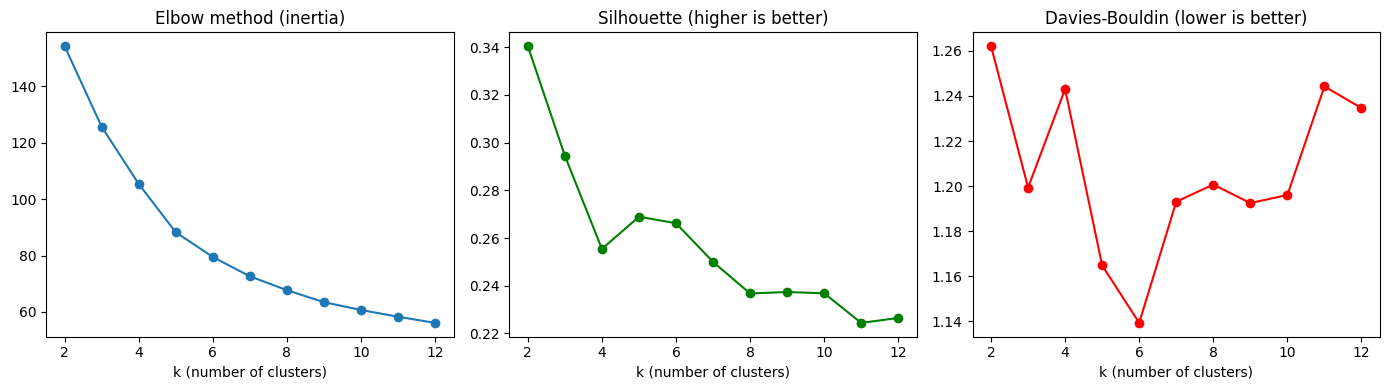

,k,inertia,silhouette,davies_bouldin
0,2,154.0,0.340,1.262
1,3,126.0,0.294,1.199
2,4,105.0,0.255,1.243
3,5,88.0,0.269,1.165
4,6,79.0,0.266,1.139
5,7,73.0,0.250,1.193
6,8,68.0,0.237,1.201
7,9,63.0,0.237,1.192
8,10,61.0,0.237,1.196
9,11,58.0,0.224,1.244


In [26]:
k_values = range(2, 13)

# empty lists to store the scores
inertia, sil, dbi = [], [], []

for k in k_values:

  # train K-Means with k clusters
    km = KMeans(n_clusters=k, n_init=5, random_state=42).fit(X_s)
    # elbow score
    inertia.append(km.inertia_)
    # silhouette is slow, so it is calculated on 10,000 points
    sil.append(silhouette_score(X_s, km.labels_, sample_size=10000, random_state=42))
    dbi.append(davies_bouldin_score(X_s, km.labels_))

# Draw the three scores side by side
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(k_values, inertia, marker='o'); ax[0].set_title('Elbow method (inertia)')
ax[1].plot(k_values, sil, marker='o', color='green'); ax[1].set_title('Silhouette (higher is better)')
ax[2].plot(k_values, dbi, marker='o', color='red'); ax[2].set_title('Davies-Bouldin (lower is better)')
for a in ax: a.set_xlabel('k (number of clusters)')
plt.tight_layout(); plt.show()

# The same numbers as a table
pd.DataFrame({'k': list(k_values), 'inertia': np.round(inertia), 'silhouette': np.round(sil, 3), 'davies_bouldin': np.round(dbi, 3)})

**Choosing k:** the inertia (elbow) curve bends gradually and starts to flatten around k = 4–6. The Davies-Bouldin score is also low around k = 5–6.
The silhouette score is highest at k = 2, but two groups are too broad for ride matching. Silhouette scores are moderate (about 0.27) because trips form a continuous spread, not clearly separated groups, which is normal for route data.
We use **k = 5**: it is at the elbow, gives a good Davies-Bouldin score, and gives a small number of clear route groups.

### (b) Fit the final model with a train/test split
We train the model on 80% of the trips and keep 20% hidden. The hidden 20% (the test set) lets us check that the model works on trips it has never seen.

In [27]:
# number of clusters chosen above

K = 5
# 80% of trips to train, 20% to test
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)

# Train K-Means on the training trips
# n_init=10 means it tries 10 starting positions and keeps the best one
model = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_train)
print('Model trained on', len(X_train), 'trips')

Model trained on 1297236 trips


### (c) Validate on unseen data
If the model is good, the scores on the test trips should be close to the scores on the training trips. If the test scores are much worse, the model has only memorised the training data.
We also re-run K-Means with different random starts: a stable model should give similar results each time.

In [28]:
# cluster of each training trip
train_labels = model.labels_
   # cluster of each unseen test trip
test_labels = model.predict(X_test)

# Silhouette and Davies-Bouldin on train vs test (silhouette uses a 10,000 sample)
print('Silhouette  train:', round(silhouette_score(X_train, train_labels, sample_size=10000, random_state=42), 3),
      '| test:', round(silhouette_score(X_test, test_labels, sample_size=10000, random_state=42), 3))
print('Davies-Bouldin train:', round(davies_bouldin_score(X_train, train_labels), 3),
      '| test:', round(davies_bouldin_score(X_test, test_labels), 3))

# Average squared distance of a trip to its cluster centre (similar numbers = no overfitting)
print('Avg distance to centre  train:', round(model.inertia_ / len(X_train) * 1e4, 4),
      '| test:', round(-model.score(X_test) / len(X_test) * 1e4, 4), '(x 1e-4)')

Silhouette  train: 0.272 | test: 0.271
Davies-Bouldin train: 1.165 | test: 1.165
Avg distance to centre  train: 8.879 | test: 8.8763 (x 1e-4)


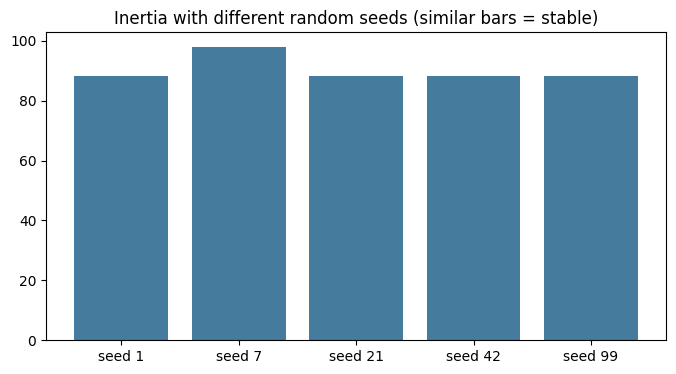

In [29]:
# Stability check: train with 5 different random seeds and compare inertia
inertias = []
for seed in [1, 7, 21, 42, 99]:
    m = KMeans(n_clusters=K, n_init=1, random_state=seed).fit(X_s)
    inertias.append(m.inertia_)

plt.bar(['seed 1', 'seed 7', 'seed 21', 'seed 42', 'seed 99'], inertias, color='#457b9d')
plt.title('Inertia with different random seeds (similar bars = stable)'); plt.show()

**What we found:** the train and test scores are almost the same, so the model is not overfitting. The seed check gives similar inertia each time (the bars are about equal), so the clusters are stable.

### (d) Results: the route clusters
Now we give every trip its cluster number and look at what each cluster means: where its trips usually start and end, how big it is, and when it is busy.

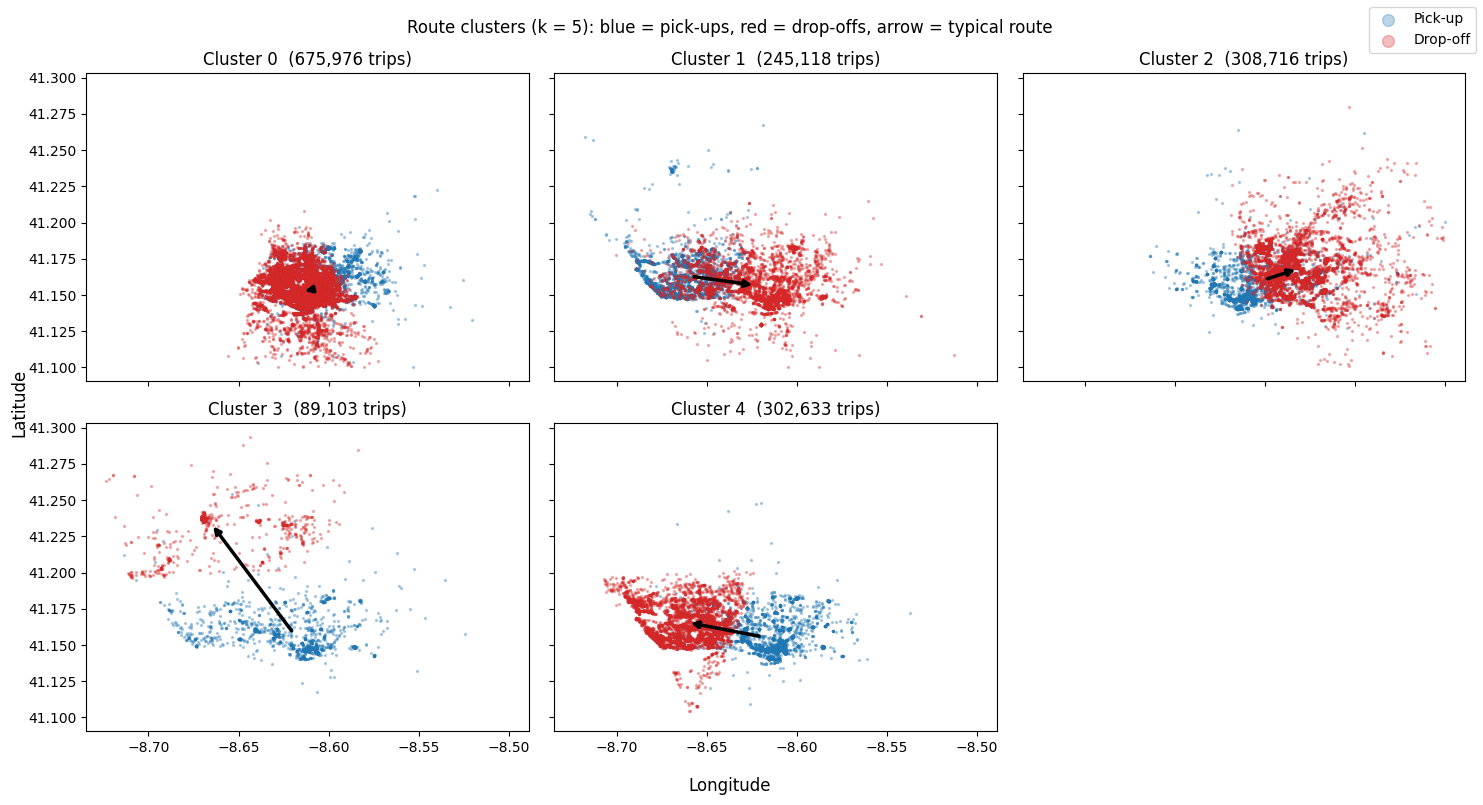

In [37]:
import numpy as np
import matplotlib.pyplot as plt

df['cluster'] = model.predict(df[['slat', 'slon', 'tlat', 'tlon']])
centers = pd.DataFrame(model.cluster_centers_, columns=['slat', 'slon', 'tlat', 'tlon'])

sample = df.sample(min(30000, len(df)), random_state=1)

ncols = 3
nrows = int(np.ceil(K / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows),
                         sharex=True, sharey=True)   # same map extent in every panel
axes = np.array(axes).ravel()

for i in range(K):
    ax = axes[i]
    s = sample[sample['cluster'] == i]
    ax.scatter(s['slon'], s['slat'], s=2, alpha=0.3, c='tab:blue', label='Pick-up')
    ax.scatter(s['tlon'], s['tlat'], s=2, alpha=0.3, c='tab:red',  label='Drop-off')

    # typical route of this cluster
    c = centers.loc[i]
    ax.annotate('', xy=(c['tlon'], c['tlat']), xytext=(c['slon'], c['slat']),
                arrowprops=dict(arrowstyle='-|>', color='black', lw=2.5))

    ax.set_title(f'Cluster {i}  ({(df["cluster"] == i).sum():,} trips)')

for ax in axes[K:]:          # hide unused panels
    ax.axis('off')

h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='upper right', markerscale=6)
fig.supxlabel('Longitude'); fig.supylabel('Latitude')
fig.suptitle(f'Route clusters (k = {K}): blue = pick-ups, red = drop-offs, arrow = typical route')
plt.tight_layout()
plt.show()

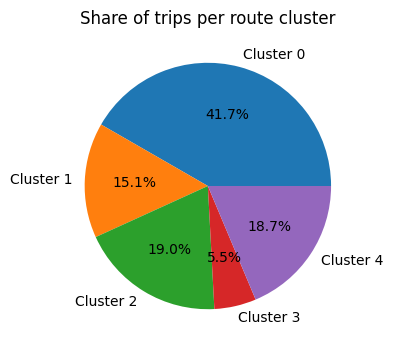

In [31]:
# Pie chart: share of all trips that belongs to each cluster
sizes = df['cluster'].value_counts().sort_index()
plt.pie(sizes, labels=[f'Cluster {i}' for i in sizes.index], autopct='%1.1f%%', colors=plt.cm.tab10.colors)
plt.title('Share of trips per route cluster')
plt.show()

In [32]:
# Summary table for each cluster: typical route, number of trips, average distance, busiest hour
summary = centers.copy()
summary['trips'] = sizes.values
summary['avg_trip_km'] = df.groupby('cluster')['km'].mean().round(2).values
summary['busiest_hour'] = df.groupby('cluster')['hour'].agg(lambda h: h.value_counts().idxmax()).values
summary.round(4)

,slat,slon,tlat,tlon,trips,avg_trip_km,busiest_hour
0,41.1537,-8.6091,41.1522,-8.6146,675976,2.05,9
1,41.1629,-8.6585,41.1567,-8.6232,245118,3.57,9
2,41.1605,-8.6002,41.1680,-8.5817,308716,3.10,9
3,41.1583,-8.6196,41.2335,-8.6650,89103,9.55,4
4,41.1558,-8.6196,41.1655,-8.6604,302633,3.98,9


**What we found:** most trips fall in a few clusters, and the clusters differ in length and busy time. For example, one small cluster has much longer trips (about 9.5 km) heading north, which may be airport trips. Short central trips make up the biggest cluster.

### Matching demo: how the app would use the model
UniPool needs to find riders who can share a ride. Two riders are good match candidates if their trips are in the **same route cluster** and their request times are **close together**. The demo below tests this idea.

In [33]:
# Pick one random trip and count other trips in the SAME cluster within 15 minutes of it
# These are the riders who could share a ride with this one
trip = df.sample(1, random_state=7).iloc[0]
same_cluster = df[df['cluster'] == trip['cluster']]
window = same_cluster[(same_cluster['timestamp'] - trip['timestamp']).abs() <= pd.Timedelta(minutes=15)]

print('Request time:', trip['timestamp'], '| route cluster:', trip['cluster'])
# minus 1 = the trip itself
print('Possible ride-share matches within 15 minutes:', len(window) - 1)

Request time: 2013-09-11 19:06:13 | route cluster: 1
Possible ride-share matches within 15 minutes: 13


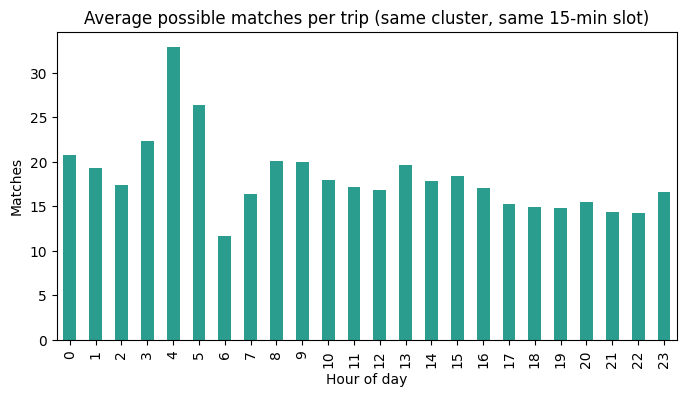

In [34]:
# How many possible matches does a typical trip have at each hour? (using one month of data, May 2014)
one_month = df[df['timestamp'].dt.to_period('M') == '2014-05'].copy()
 # round time down to 15-minute slots

one_month['slot'] = one_month['timestamp'].dt.floor('15min')
# trips per cluster per slot
slot_counts = one_month.groupby(['cluster', 'slot']).size()
# matches for a trip = other trips in the same cluster and slot
one_month['matches'] = slot_counts.reindex(list(zip(one_month['cluster'], one_month['slot']))).values - 1

one_month.groupby('hour')['matches'].mean().plot(kind='bar', color='#2a9d8f')
plt.title('Average possible matches per trip (same cluster, same 15-min slot)')
plt.xlabel('Hour of day'); plt.ylabel('Matches')
plt.show()

**What we found:** about 96% of trips have at least 3 possible matches, and the average is about 18. The number of matches does not follow the busy hours closely: it stays between about 11 and 33 at every hour of the day, with the highest value around 4 AM.
**Note:** Porto has hundreds of taxis, so these numbers are much higher than a university campus will have. This demo only shows the matching idea works; real UniPool numbers must be tested with Strathmore data.

## 5. Further validation with other models (Q4)
To check that K-Means gives a reasonable result, we run other clustering models on the **same data and same k** and compare their scores. If different models give similar quality, we can trust the base model more.

| Model | Why we use it |
|---|---|
| **K-Means** (base) | Simple, fast, easy to explain |
| **MiniBatch K-Means** | Faster version of K-Means, so it should give almost the same result |
| **Gaussian Mixture** | Allows clusters of different shapes and sizes instead of round ones |

We compare silhouette (higher is better) and Davies-Bouldin (lower is better). In the final notebook we can add more models (e.g. Agglomerative, DBSCAN) and compare them like Figure 6 of the reference paper.

In [35]:
# The three models, all with the same number of clusters
models = {
    'K-Means': KMeans(n_clusters=K, n_init=10, random_state=42),
    'MiniBatch K-Means': MiniBatchKMeans(n_clusters=K, n_init=10, random_state=42),
    'Gaussian Mixture': GaussianMixture(n_components=K, random_state=42),
}

results = []
for name, m in models.items():
  # train on the same 100,000 sample and get cluster labels
    labels = m.fit_predict(X_s)
    results.append({'Model': name,
                    'Silhouette': silhouette_score(X_s, labels, sample_size=10000, random_state=42),
                    'Davies-Bouldin': davies_bouldin_score(X_s, labels)})

results = pd.DataFrame(results).round(3)
results

,Model,Silhouette,Davies-Bouldin
0,K-Means,0.269,1.163
1,MiniBatch K-Means,0.265,1.191
2,Gaussian Mixture,0.184,1.611


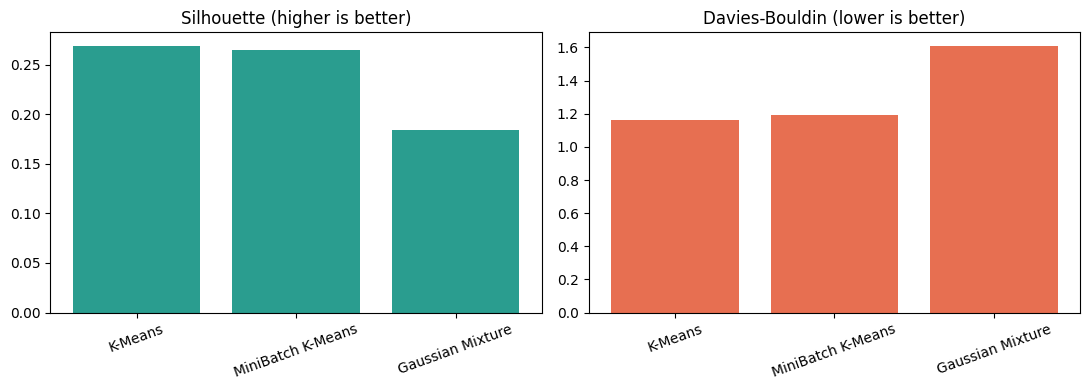

In [36]:
# Bar charts comparing the models
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(results['Model'], results['Silhouette'], color='#2a9d8f'); ax[0].set_title('Silhouette (higher is better)')
ax[1].bar(results['Model'], results['Davies-Bouldin'], color='#e76f51'); ax[1].set_title('Davies-Bouldin (lower is better)')
for a in ax: a.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

**What we found:** MiniBatch K-Means scores almost the same as K-Means, which supports our base model. Gaussian Mixture scores worse on both measures, so K-Means is a good choice for this data.

## Conclusion
K-Means grouped the trips into route clusters. The scores on the test data are close to the training scores and the result stays similar for different random seeds, so the model is stable.
In UniPool, a new ride request would be assigned to its nearest route cluster, and riders in the same cluster with a similar request time become match candidates (see the matching demo).